# Análise e Comparação de Modelos — Predição de Diabetes

Este projeto utiliza o conjunto de dados Pima Indians Diabetes, trabalhado durante um curso de Machine Learning da Universidade Estadual do Ceará (UECE), para explorar os dados e comparar diferentes modelos de classificação.

**Objetivo:** investigar os dados, preparar as variáveis e comparar o desempenho de oito modelos na previsão da variável `Outcome`.

> `Outcome = 0`: classe sem diabetes.  
> `Outcome = 1`: classe com diabetes.

Este é um projeto educacional de aprendizado de máquina. Os resultados não devem ser utilizados para diagnóstico ou decisões médicas.

## 1. Importações e configuração do projeto

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Localiza a raiz do projeto, mesmo que o notebook seja executado
PASTA_ATUAL = Path.cwd()
ROOT = PASTA_ATUAL

while not ((ROOT / "src").is_dir() and (ROOT / "data").is_dir()):
    if ROOT.parent == ROOT:
        raise FileNotFoundError(
            "Não foi possível localizar a raiz do projeto. "
            "Verifique se as pastas 'src' e 'data' existem."
        )
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data_preprocessing import DiabetesDataPipeline
from src.models import ModelBenchmark

DATA_PATH = ROOT / "data" / "diabetes.csv"
OUTPUTS_PATH = ROOT / "outputs"
OUTPUTS_PATH.mkdir(exist_ok=True)

print("Projeto configurado com sucesso!")

Projeto configurado com sucesso!


## 2. Carregamento dos dados

In [2]:
pipeline = DiabetesDataPipeline(DATA_PATH)

df_original = pipeline.load_data()

print("Dimensões do conjunto:", df_original.shape)
display(df_original.head())

Dimensões do conjunto: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 3. Análise exploratória dos dados (EDA)

In [3]:
print("Informações gerais:")
df_original.info()

Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
print("Valores ausentes originalmente:")
display(df_original.isna().sum().to_frame("Valores ausentes"))

Valores ausentes originalmente:


,Valores ausentes
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [5]:
print("Quantidade de zeros por coluna:")
display((df_original == 0).sum().to_frame("Quantidade de zeros"))

Quantidade de zeros por coluna:


,Quantidade de zeros
Pregnancies,111
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,500


In [6]:
print("Distribuição da variável-alvo (Outcome):")
display(df_original["Outcome"].value_counts().sort_index().rename(index={
    0: "Sem diabetes (0)",
    1: "Com diabetes (1)"
}).to_frame("Quantidade"))

print("\nProporção das classes:")
display(df_original["Outcome"].value_counts(normalize=True).sort_index().round(3))

Distribuição da variável-alvo (Outcome):


,Quantidade
Outcome,
Sem diabetes (0),500
Com diabetes (1),268



Proporção das classes:


Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64

In [7]:
colunas_zeros_suspeitos = [
    "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"
]

print("Zeros por classe nas variáveis em que zero é tratado como ausência:")
for coluna in colunas_zeros_suspeitos:
    print(f"\\n{coluna}")
    for classe in [0, 1]:
        grupo = df_original[df_original["Outcome"] == classe]
        quantidade = (grupo[coluna] == 0).sum()
        total = len(grupo)
        print(f"  Outcome {classe}: {quantidade}/{total} ({quantidade / total:.1%})")

Zeros por classe nas variáveis em que zero é tratado como ausência:
\nGlucose
  Outcome 0: 3/500 (0.6%)
  Outcome 1: 2/268 (0.7%)
\nBloodPressure
  Outcome 0: 19/500 (3.8%)
  Outcome 1: 16/268 (6.0%)
\nSkinThickness
  Outcome 0: 139/500 (27.8%)
  Outcome 1: 88/268 (32.8%)
\nInsulin
  Outcome 0: 236/500 (47.2%)
  Outcome 1: 138/268 (51.5%)
\nBMI
  Outcome 0: 9/500 (1.8%)
  Outcome 1: 2/268 (0.7%)


In [8]:
print("Estatísticas descritivas das variáveis:")
display(df_original.describe().T.round(2))

Estatísticas descritivas das variáveis:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


## 4. Tratamento dos dados

Os zeros encontrados em Glucose, BloodPressure, SkinThickness, Insulin e BMI foram substituídos por valores ausentes (NaN).

A substituição dos valores ausentes pela mediana é feita durante o treinamento de cada modelo, por meio dos pipelines. Assim, o cálculo da mediana não utiliza os dados de teste.

In [9]:
df_limpo = pipeline.clean_data()

print("Dimensões após o tratamento:", df_limpo.shape)
print("Valores ausentes por coluna após identificar zeros:")
display(df_limpo.isna().sum().to_frame("Valores ausentes"))

Dimensões após o tratamento: (768, 9)
Valores ausentes por coluna após identificar zeros:


,Valores ausentes
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


## 5. Separação dos dados em treino e teste

Os dados foram divididos em dois conjuntos: 80% para treinamento e 20% para teste.

A divisão utiliza estratificação pela variável `Outcome` e `random_state=42`, mantendo a proporção das classes entre os conjuntos.

In [10]:
X_train, X_test, y_train, y_test, colunas = pipeline.prepare_train_test()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\\nValores ausentes em X_train:", X_train.isna().sum().sum())
print("Valores ausentes em X_test:", X_test.isna().sum().sum())

X_train: (614, 8)
X_test: (154, 8)
y_train: (614,)
y_test: (154,)
\nValores ausentes em X_train: 501
Valores ausentes em X_test: 151


## 6. Treinamento e comparação dos modelos

Foram utilizados oito modelos: Dummy Classifier, Regressão Logística, KNN, SVM, MLP, Árvore de Decisão, Random Forest e Gradient Boosting.

O treinamento e a avaliação são realizados pela classe `ModelBenchmark`, localizada em `src/models.py`.

In [11]:
benchmark = ModelBenchmark()

resultados = benchmark.train_and_evaluate(
    X_train,
    X_test,
    y_train,
    y_test
)

display(
    resultados.sort_values("F1-Score", ascending=False).round(4)
)

,Accuracy,Precision,Recall (Sensibilidade),F1-Score,ROC-AUC,CV Mean Accuracy,CV Std Accuracy
Decision Tree,0.785714,0.698113,0.685185,0.691589,0.788704,0.732947,0.04318
Random Forest,0.766234,0.695652,0.592593,0.64,0.821019,0.760602,0.018752
K-Nearest Neighbors (KNN),0.753247,0.66,0.611111,0.634615,0.789907,0.729588,0.040679
Neural Network (MLP),0.727273,0.603448,0.648148,0.625,0.803148,0.732867,0.031724
Gradient Boosting,0.753247,0.681818,0.555556,0.612245,0.830926,0.755684,0.018019
Support Vector Machine (SVM),0.74026,0.652174,0.555556,0.6,0.796296,0.780128,0.013623
Logistic Regression,0.707792,0.6,0.5,0.545455,0.812963,0.788231,0.019057
Baseline (Dummy),0.597403,0.416667,0.37037,0.392157,0.545185,0.578155,0.019912


### Tabela consolidada

In [12]:
colunas_resultados = [
    "Accuracy",
    "Precision",
    "Recall (Sensibilidade)",
    "F1-Score",
    "ROC-AUC",
    "CV Mean Accuracy",
    "CV Std Accuracy"
]

tabela_final = resultados[colunas_resultados].sort_values(
    by="F1-Score",
    ascending=False
)

display(tabela_final.round(4))

,Accuracy,Precision,Recall (Sensibilidade),F1-Score,ROC-AUC,CV Mean Accuracy,CV Std Accuracy
Decision Tree,0.785714,0.698113,0.685185,0.691589,0.788704,0.732947,0.04318
Random Forest,0.766234,0.695652,0.592593,0.64,0.821019,0.760602,0.018752
K-Nearest Neighbors (KNN),0.753247,0.66,0.611111,0.634615,0.789907,0.729588,0.040679
Neural Network (MLP),0.727273,0.603448,0.648148,0.625,0.803148,0.732867,0.031724
Gradient Boosting,0.753247,0.681818,0.555556,0.612245,0.830926,0.755684,0.018019
Support Vector Machine (SVM),0.74026,0.652174,0.555556,0.6,0.796296,0.780128,0.013623
Logistic Regression,0.707792,0.6,0.5,0.545455,0.812963,0.788231,0.019057
Baseline (Dummy),0.597403,0.416667,0.37037,0.392157,0.545185,0.578155,0.019912


## 7. Avaliação dos modelos

As matrizes de confusão e os relatórios de classificação abaixo detalham os resultados dos modelos Árvore de Decisão e Random Forest.

In [13]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

modelos_detalhados = ["Decision Tree", "Random Forest"]

for nome in modelos_detalhados:
    y_pred = benchmark.results[nome]["y_pred"]

    print(f"\\n{'=' * 50}\\n{nome}")
    print("Matriz de confusão:")
    print(confusion_matrix(y_test, y_pred))

    print("\\nRelatório de classificação:")
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Sem diabetes", "Com diabetes"],
            zero_division=0
        )
    )

\n==================================================\nDecision Tree
Matriz de confusão:
[[84 16]
 [17 37]]
\nRelatório de classificação:
              precision    recall  f1-score   support

Sem diabetes       0.83      0.84      0.84       100
Com diabetes       0.70      0.69      0.69        54

    accuracy                           0.79       154
   macro avg       0.76      0.76      0.76       154
weighted avg       0.78      0.79      0.79       154

\n==================================================\nRandom Forest
Matriz de confusão:
[[86 14]
 [22 32]]
\nRelatório de classificação:
              precision    recall  f1-score   support

Sem diabetes       0.80      0.86      0.83       100
Com diabetes       0.70      0.59      0.64        54

    accuracy                           0.77       154
   macro avg       0.75      0.73      0.73       154
weighted avg       0.76      0.77      0.76       154



### Matrizes de confusão

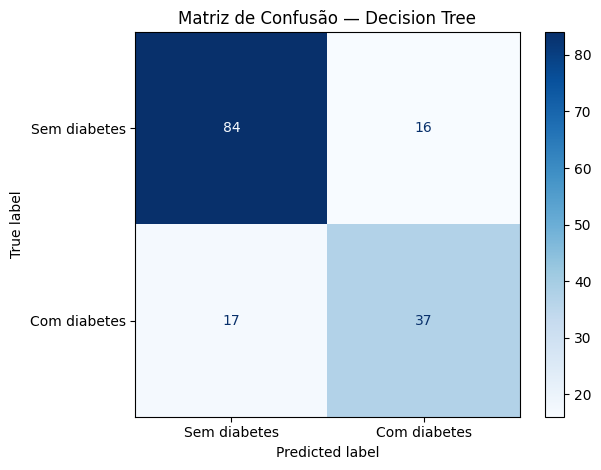

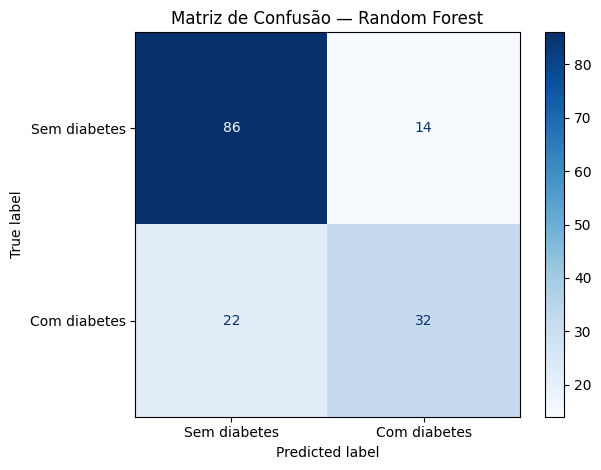

In [14]:
for nome in modelos_detalhados:
    y_pred = benchmark.results[nome]["y_pred"]

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Sem diabetes", "Com diabetes"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"Matriz de Confusão — {nome}")
    plt.tight_layout()
    plt.show()

### Importância das variáveis

A importância das variáveis é apresentada para os modelos baseados em árvores. Essa medida representa a contribuição das variáveis para as divisões realizadas pelo modelo; não indica causalidade nem relevância clínica.

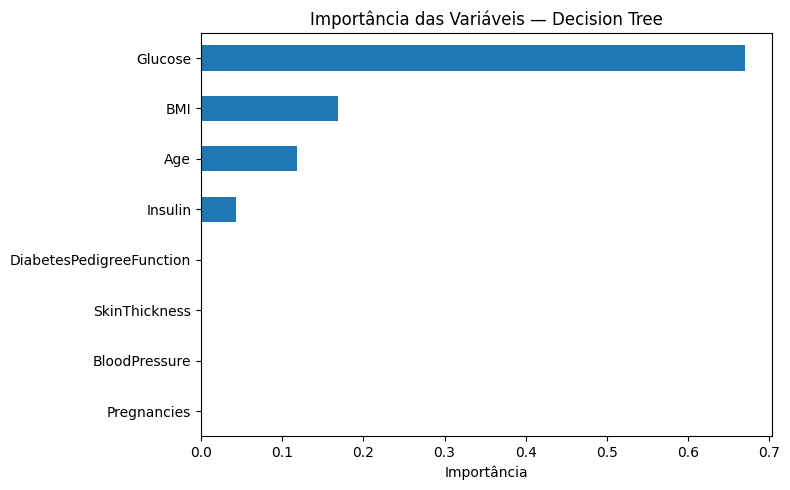

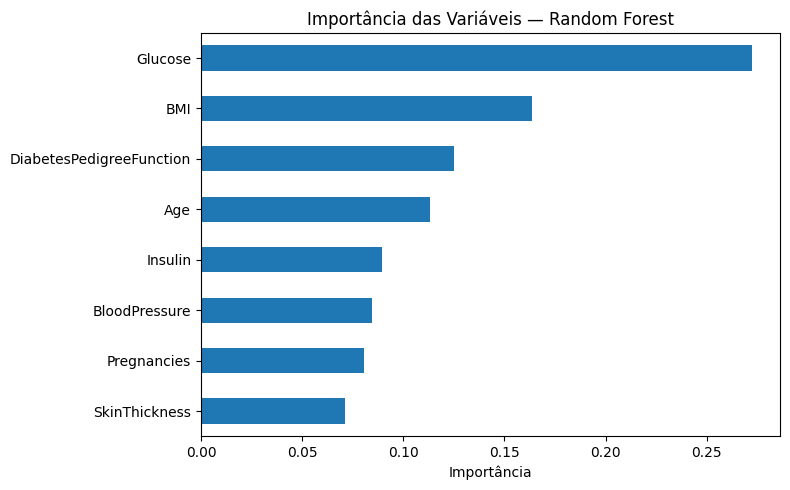

In [15]:
for nome in ["Decision Tree", "Random Forest"]:
    modelo = benchmark.results[nome]["model_object"].named_steps["modelo"]

    importancia = pd.Series(
        modelo.feature_importances_,
        index=X_train.columns
    ).sort_values()

    plt.figure(figsize=(8, 5))
    importancia.plot(kind="barh")
    plt.title(f"Importância das Variáveis — {nome}")
    plt.xlabel("Importância")
    plt.tight_layout()
    plt.show()

## 8. Visualizações gerais

### Matriz de correlação

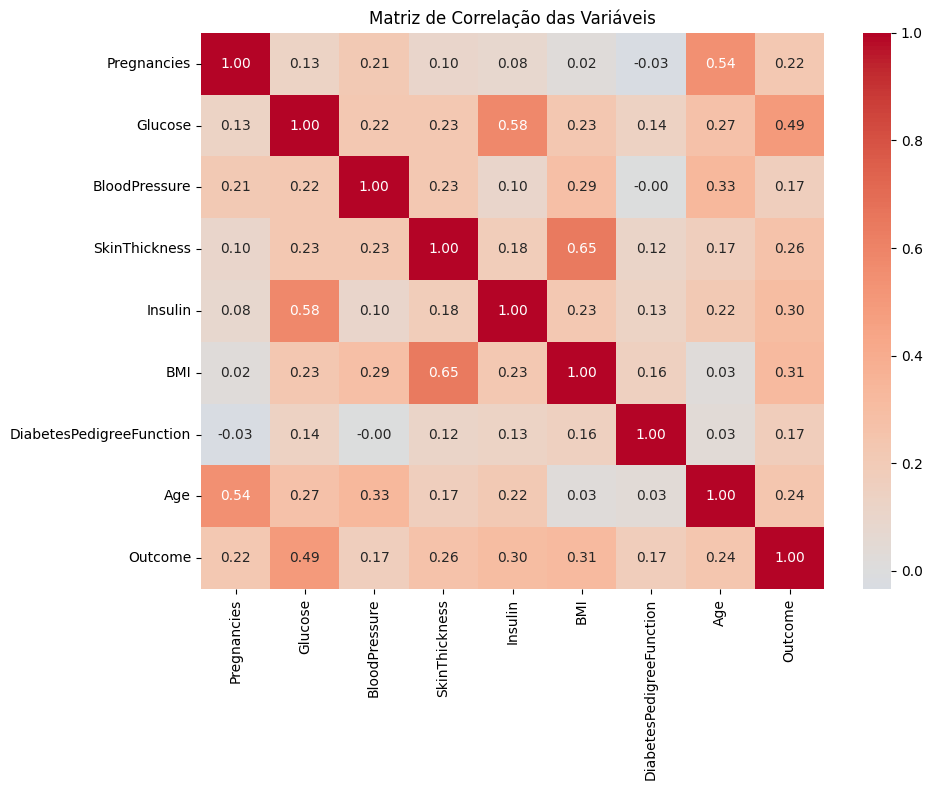

Gráfico de comparação salvo com sucesso!


In [16]:
correlacao = df_limpo.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)
plt.title("Matriz de Correlação das Variáveis")
plt.tight_layout()

caminho_correlacao = OUTPUTS_PATH / "matriz_correlacao.png"
plt.savefig(caminho_correlacao, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Gráfico de comparação salvo com sucesso!")

### Comparação dos modelos pelo F1-score

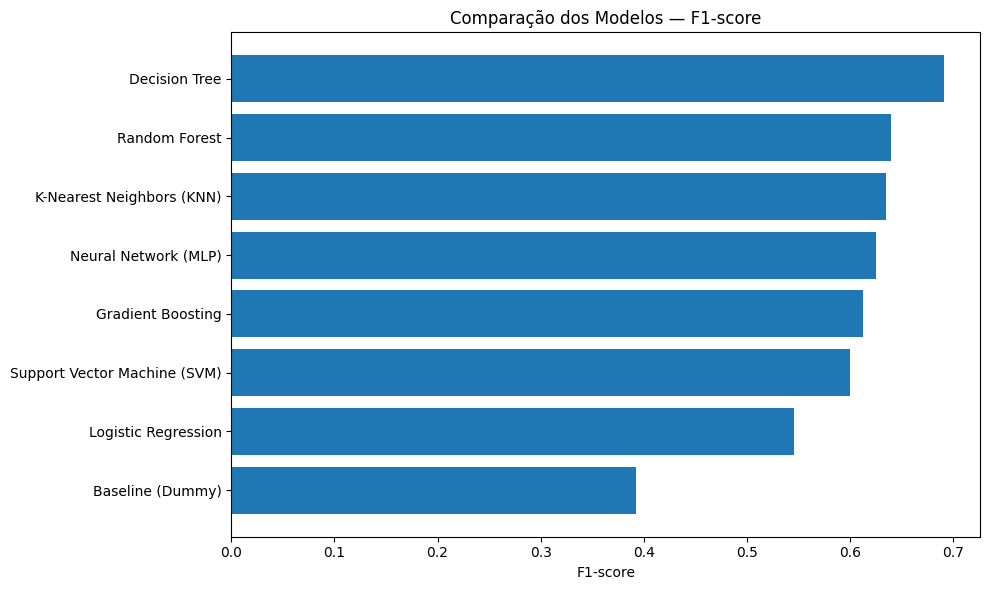

Gráfico de comparação salvo com sucesso!


In [17]:
resultados_grafico = resultados[["F1-Score"]].sort_values("F1-Score")

plt.figure(figsize=(10, 6))
plt.barh(resultados_grafico.index, resultados_grafico["F1-Score"])
plt.xlabel("F1-score")
plt.title("Comparação dos Modelos — F1-score")
plt.tight_layout()

caminho_comparacao = OUTPUTS_PATH / "comparacao_modelos.png"
plt.savefig(caminho_comparacao, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Gráfico de comparação salvo com sucesso!")

## 9. Síntese dos resultados

In [18]:
melhor_f1 = resultados["F1-Score"].idxmax()
melhor_auc = resultados["ROC-AUC"].idxmax()
melhor_accuracy = resultados["Accuracy"].idxmax()

print(f"Maior F1-score: {melhor_f1} ({resultados.loc[melhor_f1, 'F1-Score']:.4f})")
print(f"Maior ROC-AUC: {melhor_auc} ({resultados.loc[melhor_auc, 'ROC-AUC']:.4f})")
print(f"Maior acurácia: {melhor_accuracy} ({resultados.loc[melhor_accuracy, 'Accuracy']:.4f})")

Maior F1-score: Decision Tree (0.6916)
Maior ROC-AUC: Gradient Boosting (0.8309)
Maior acurácia: Decision Tree (0.7857)


### Considerações finais

Nos testes realizados, a Árvore de Decisão apresentou a maior acurácia (78,57%) e o maior F1-score (69,16%). Já o Gradient Boosting obteve o maior ROC-AUC (83,09%).

Os resultados mostram que não existe um único modelo com o melhor desempenho em todas as métricas. Por isso, é importante considerar o objetivo da análise antes de escolher um modelo.

Este experimento foi realizado com um conjunto de dados específico e uma divisão entre treino e teste. Os resultados não garantem o mesmo desempenho em outros dados e não devem ser utilizados para diagnóstico médico.